<a href="https://colab.research.google.com/github/wassimelboulahfati-OC/OC_project/blob/main/Projet2_Analyse_des_donn%C3%A9es_SE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [140]:
import numpy as np
import pandas as pd
import seaborn as sbn
import matplotlib.pyplot as plt
from google.colab import drive

In [141]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [142]:
pd.set_option('display.max_columns', None)

In [143]:
pd.set_option('display.max_rows', None)

# Exercice Partie 1


In [144]:
#Création d'une fonction pour faciliter la lecture des fichiers csv
def readcsv(df_name = str):
  df_name = pd.read_csv(f"/content/drive/My Drive/Projet1_data/{df_name}.csv", delimiter = ",")
  return df_name

## **Traitement de base des fichiers (couche bronze)**

Extraction du fichier EdStatsCountry dans un dataframe.
Chaque ligne représente un pays avec un code pays unique et un certain nombre d'indicateurs.

Avant traitement le dataframe contient 241 lignes et 32 colonnes.

In [145]:
brz_EdStatsCountry = readcsv("EdStatsCountry")
brz_EdStatsCountry.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,National accounts base year,National accounts reference year,SNA price valuation,Lending category,Other groups,System of National Accounts,Alternative conversion factor,PPP survey year,Balance of Payments Manual in use,External debt Reporting status,System of trade,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from official government statistics; 1994-1999 from UN databases. Base year has changed from 1995 to 2000.,Latin America & Caribbean,High income: nonOECD,AW,2000,NaN,Value added at basic prices (VAB),NaN,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,NaN,"IMF Balance of Payments Manual, 6th edition.",NaN,Special trade system,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period for national accounts data: FY (from 2013 are CY). National accounts data are sourced from the IMF and differ from the Central Statistics Organization numbers due to exclusion of the opium economy.,South Asia,Low income,AF,2002/03,NaN,Value added at basic prices (VAB),IDA,HIPC,Country uses the 1993 System of National Accounts methodology.,NaN,NaN,NaN,Actual,General trade system,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data, national accounts data were revised for 2000 onward; the base year changed to 2002.",Sub-Saharan Africa,Upper middle income,AO,2002,NaN,Value added at producer prices (VAP),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,1991–96,2005,"IMF Balance of Payments Manual, 6th edition.",Actual,Special trade system,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,Original chained constant price data are rescaled.,1996.0,Value added at basic prices (VAB),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,Rolling,"IMF Balance of Payments Manual, 6th edition.",Actual,General trade system,Budgetary central government,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09","Living Standards Measurement Study Survey (LSMS), 2012",Yes,2012,2010.0,2012.0,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,1990,NaN,NaN,NaN,NaN,Country uses the 1968 System of National Accounts methodology.,NaN,NaN,NaN,NaN,Special trade system,NaN,NaN,2011. Population figures compiled from administrative registers.,NaN,NaN,Yes,NaN,NaN,2006.0,NaN,NaN


In [146]:
brz_EdStatsCountry.shape

(241, 32)

In [147]:
"""
Affichage des types, certains types ne sont pas cohérent il faudra les corrigés pour pouvoir les traités.
"""
brz_EdStatsCountry.dtypes

,0
Country Code,object
Short Name,object
Table Name,object
Long Name,object
2-alpha code,object
Currency Unit,object
Special Notes,object
Region,object
Income Group,object
WB-2 code,object


In [148]:
brz_EdStatsCountry.duplicated('Country Code').sum()

np.int64(0)

In [149]:
coles_vides = [col for col in brz_EdStatsCountry.columns if brz_EdStatsCountry[col].isnull().all()]
brz_EdStatsCountry.drop(coles_vides, axis = 1 , inplace= True)

In [150]:
coles_inutilsables = [col for col in brz_EdStatsCountry.columns if brz_EdStatsCountry[col].isna().mean() > 0.8]
brz_EdStatsCountry.drop(coles_inutilsables, axis = 1 , inplace= True)

In [151]:
brz_EdStatsCountry.isna().mean()

,0
Country Code,0.000000
Short Name,0.000000
Table Name,0.000000
Long Name,0.000000
2-alpha code,0.012448
Currency Unit,0.107884
Special Notes,0.398340
Region,0.112033
Income Group,0.112033
WB-2 code,0.004149


In [152]:
colonnes_objet = brz_EdStatsCountry.select_dtypes(include="object")

for col in colonnes_objet.columns:
    print(f"\nOccurrences dans la colonne '{col}':")
    print(colonnes_objet[col].value_counts())


Occurrences dans la colonne 'Country Code':
Country Code
ABW    1
AFG    1
AGO    1
ALB    1
AND    1
ARB    1
ARE    1
ARG    1
ARM    1
ASM    1
ATG    1
AUS    1
AUT    1
AZE    1
BDI    1
BEL    1
BEN    1
BFA    1
BGD    1
BGR    1
BHR    1
BHS    1
BIH    1
BLR    1
BLZ    1
BMU    1
BOL    1
BRA    1
BRB    1
BRN    1
BTN    1
BWA    1
CAF    1
CAN    1
CHE    1
CHI    1
CHL    1
CHN    1
CIV    1
CMR    1
COD    1
COG    1
COL    1
COM    1
CPV    1
CRI    1
CUB    1
CUW    1
CYM    1
CYP    1
CZE    1
DEU    1
DJI    1
DMA    1
DNK    1
DOM    1
DZA    1
EAP    1
EAS    1
ECA    1
ECS    1
ECU    1
EGY    1
EMU    1
ERI    1
ESP    1
EST    1
ETH    1
EUU    1
FIN    1
FJI    1
FRA    1
FRO    1
FSM    1
GAB    1
GBR    1
GEO    1
GHA    1
GIB    1
GIN    1
GMB    1
GNB    1
GNQ    1
GRC    1
GRD    1
GRL    1
GTM    1
GUM    1
GUY    1
HIC    1
HKG    1
HND    1
HPC    1
HRV    1
HTI    1
HUN    1
IDN    1
IMN    1
IND    1
IRL    1
IRN    1
IRQ    1
ISL    1
ISR    1
ITA   

# **Deuxième fichier**

Extraction du fichier EdStatsCountrySeries dans un dataframe. Chaque ligne représente une serie de code particulier affilié à une description certains code pays réaparaissent plusieurs fois, il est possible qu'il y ait des doublons. Cette table permet de sourcer les données.

Avant traitement le dataframe contient 613 lignes et 4 colonnes.

In [153]:
brz_EdStatsCountrySeries = readcsv("EdStatsCountry-Series")
brz_EdStatsCountrySeries.head()

,CountryCode,SeriesCode,DESCRIPTION,Unnamed: 3
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population Prospects,NaN
1,ABW,SP.POP.GROW,Data sources: United Nations World Population Prospects,NaN
2,AFG,SP.POP.GROW,Data sources: United Nations World Population Prospects,NaN
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.,NaN
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population Prospects,NaN


In [154]:
brz_EdStatsCountrySeries.shape

(613, 4)

In [155]:
brz_EdStatsCountrySeries.dtypes

,0
CountryCode,object
SeriesCode,object
DESCRIPTION,object
Unnamed: 3,float64


Les types paraissent cohérent.

In [156]:
brz_EdStatsCountrySeries.duplicated().sum()

np.int64(0)

Il n'y a pas de doublon dans le data frame chaque ligne est unique.

In [157]:
coles_vides = [col for col in brz_EdStatsCountrySeries.columns if brz_EdStatsCountrySeries[col].isnull().all()]
brz_EdStatsCountrySeries.drop(coles_vides, axis = 1 , inplace= True)
brz_EdStatsCountrySeries.head()

,CountryCode,SeriesCode,DESCRIPTION
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population Prospects
1,ABW,SP.POP.GROW,Data sources: United Nations World Population Prospects
2,AFG,SP.POP.GROW,Data sources: United Nations World Population Prospects
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population Prospects


In [158]:
brz_EdStatsCountrySeries.isna().mean()

,0
CountryCode,0.0
SeriesCode,0.0
DESCRIPTION,0.0


Il n'y a aucune valeur manquante.

In [159]:
colonnes_objet = brz_EdStatsCountrySeries.select_dtypes(include="object")

for col in colonnes_objet.columns:
    print(f"\nOccurrences dans la colonne '{col}':")
    print(colonnes_objet[col].value_counts())


Occurrences dans la colonne 'CountryCode':
CountryCode
GEO    18
MDA    18
CYP    12
SRB    12
MUS    12
MAR    12
TZA    12
GUY     8
ERI     8
ARG     8
SOM     8
LBN     8
LBY     8
SMR     8
PRI     8
TLS     8
TKM     8
SYR     8
AFG     8
UZB     8
XKX     8
MYS     6
FRA     6
CHI     6
CHN     6
AUS     6
PSE     6
VEN     3
BRB     2
BRA     2
BRN     2
BLZ     2
BMU     2
BTN     2
BHR     2
BGR     2
BGD     2
BFA     2
BEN     2
BEL     2
BDI     2
AZE     2
CMR     2
COM     2
CPV     2
CUB     2
CRI     2
BWA     2
CAF     2
BOL     2
BLR     2
DJI     2
DEU     2
CZE     2
CYM     2
DZA     2
ECU     2
DOM     2
DMA     2
ESP     2
EST     2
FIN     2
ETH     2
FJI     2
FRO     2
BIH     2
BHS     2
CHE     2
CAN     2
CIV     2
CHL     2
COD     2
COG     2
COL     2
AGO     2
AUT     2
ABW     2
AND     2
ALB     2
ARE     2
ARM     2
ASM     2
ATG     2
HND     2
HKG     2
GUM     2
GTM     2
GRD     2
GRL     2
GRC     2
GNQ     2
GIB     2
GNB     2
GMB     2
GIN 

# **Troisième fichier**

Extraction du fichier EdStatsCountrySeries dans un dataframe. Chaque ligne représente un indicateur particulier associé a un code indicateur. Il y a plusieurs indicateurs par pays. Ces indicateurs ont était observées sur une periode donnée allant de 1970 à 2100. Certaines lignes et colonnes paraissent vide.

Avant traitement le dataframe contient 886930 lignes et 70 colonnes.

In [160]:
brz_EdStatsData = readcsv("EdStatsData")
brz_EdStatsData.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2020,2025,2030,2035,2040,2045,2050,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, both sexes (%)",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, female (%)",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, male (%)",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sexes (%)",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,60.999962,61.92268,62.69342,64.383186,65.617767,66.085152,66.608139,67.290451,68.510094,69.033211,69.944908,71.04187,71.693779,71.699097,71.995819,72.602837,70.032722,70.464821,72.645683,71.81176,73.903511,74.425201,75.110817,76.254318,77.245682,78.800522,80.051399,80.805389,81.607063,82.489487,82.685509,83.280342,84.011871,84.195961,85.211998,85.24514,86.101669,85.51194,85.320152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [161]:
brz_EdStatsData.shape

(886930, 70)

In [162]:
brz_EdStatsData.dtypes

,0
Country Name,object
Country Code,object
Indicator Name,object
Indicator Code,object
1970,float64
1971,float64
1972,float64
1973,float64
1974,float64
1975,float64


Les types paraissent cohérent.

In [163]:
brz_EdStatsData.duplicated().sum()

np.int64(0)

Il n'y a pas de doublon dans le data frame chaque ligne est unique.

In [164]:
coles_vides = [col for col in brz_EdStatsData.columns if brz_EdStatsData[col].isnull().all()]
brz_EdStatsData.drop(coles_vides, axis = 1 , inplace= True)
brz_EdStatsData.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2020,2025,2030,2035,2040,2045,2050,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, both sexes (%)",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, female (%)",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, male (%)",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sexes (%)",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,60.999962,61.92268,62.69342,64.383186,65.617767,66.085152,66.608139,67.290451,68.510094,69.033211,69.944908,71.04187,71.693779,71.699097,71.995819,72.602837,70.032722,70.464821,72.645683,71.81176,73.903511,74.425201,75.110817,76.254318,77.245682,78.800522,80.051399,80.805389,81.607063,82.489487,82.685509,83.280342,84.011871,84.195961,85.211998,85.24514,86.101669,85.51194,85.320152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [165]:
brz_EdStatsData.isna().mean()

,0
Country Name,0.000000
Country Code,0.000000
Indicator Name,0.000000
Indicator Code,0.000000
1970,0.918496
1971,0.959933
1972,0.959840
1973,0.959924
1974,0.959715
1975,0.901564


Il y a beaucoup de valeurs manquantes dans les colonnes années mais il faudra ammené ca par indicateur pour voir quelles sont les indicateurs pour lesquels trop de données sont manquante (traitementpar ligne plutot que par colonne).

In [166]:
colonnes_float = brz_EdStatsData.select_dtypes(include="float")
stats_descriptives = colonnes_float.describe()
print(stats_descriptives)


               1970          1971          1972          1973          1974  \
count  7.228800e+04  3.553700e+04  3.561900e+04  3.554500e+04  3.573000e+04   
mean   1.974772e+09  4.253638e+09  4.592365e+09  5.105006e+09  5.401493e+09   
std    1.211687e+11  1.804814e+11  1.914083e+11  2.059170e+11  2.112150e+11   
min   -1.435564e+00 -1.594625e+00 -3.056522e+00 -4.032582e+00 -4.213563e+00   
25%    8.900000e-01  8.853210e+00  9.240920e+00  9.595200e+00  9.861595e+00   
50%    6.317724e+00  6.316240e+01  6.655139e+01  6.969595e+01  7.087760e+01   
75%    6.251250e+01  5.655200e+04  5.863650e+04  6.202900e+04  6.383675e+04   
max    1.903929e+13  1.986457e+13  2.100916e+13  2.238367e+13  2.282991e+13   

               1975          1976          1977          1978          1979  \
count  8.730600e+04  3.748300e+04  3.757400e+04  3.757600e+04  3.680900e+04   
mean   2.314288e+09  5.731808e+09  6.124437e+09  6.671489e+09  7.436724e+09   
std    1.375059e+11  2.215546e+11  2.325489e+11  2.

Ces statistiques descriptive ne sont pas représentative pour le moment il faut dans un premier temps traiter les données pour prendre en compte les valeurs manquantes, les lignes qui sont vides (s'il y en a), ainsi que les valeurs aberrantes. Ainsi que les comparer par indicateurs.

In [167]:
colonnes_objet = brz_EdStatsData.select_dtypes(include="object")

for col in colonnes_objet.columns:
    print(f"\nOccurrences dans la colonne '{col}':")
    print(colonnes_objet[col].value_counts())

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Population of the official age for primary education, male (number)                                                                                                     242
Population of the official age for primary education, female (number)                                                                                                   242
Population, age 11, total                                                                                                                                               242
Population, age 11, male                                                                                                                                                242
Population, age 11, female                                                                                                                                              242
Population, age 10, total                                     

# **Quatrième fichier**

Extraction du fichier EdStatsFootNote dans un dataframe. Chaque ligne représente une serie de code particulier affilié à une description certains code pays réaparaissent plusieurs fois, il est possible qu'il y ait des doublons. Cette table permet de sourcer les données.
Avant traitement le dataframe contient 643638 lignes et 4 colonnes.

In [168]:
brz_EdStatsFootNote = readcsv("EdStatsFootNote")
brz_EdStatsFootNote.head()

,CountryCode,SeriesCode,Year,DESCRIPTION,Unnamed: 4
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.,NaN
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.,NaN
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.,NaN
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.,NaN
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.,NaN


In [169]:
brz_EdStatsFootNote.shape

(643638, 5)

In [170]:
brz_EdStatsFootNote.dtypes

,0
CountryCode,object
SeriesCode,object
Year,object
DESCRIPTION,object
Unnamed: 4,float64


Les années sont mal typé dû à la manière dont a était saisie la donnée, il faudra retravaillé cette colonne dans le cas ou elle est nécessaire.

In [171]:
brz_EdStatsFootNote.duplicated().sum()

np.int64(0)

Il n'y a pas de doublons dans le dataframe.

In [172]:
coles_vides = [col for col in brz_EdStatsFootNote.columns if brz_EdStatsFootNote[col].isnull().all()]
brz_EdStatsFootNote.drop(coles_vides, axis = 1 , inplace= True)
brz_EdStatsFootNote.head()

,CountryCode,SeriesCode,Year,DESCRIPTION
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.


In [173]:
brz_EdStatsFootNote.isna().mean()

,0
CountryCode,0.0
SeriesCode,0.0
Year,0.0
DESCRIPTION,0.0


Il n'y a pas de valeur manquante

In [174]:
colonnes_objet = brz_EdStatsFootNote.select_dtypes(include="object")

for col in colonnes_objet.columns:
    print(f"\nOccurrences dans la colonne '{col}':")
    print(colonnes_objet[col].value_counts())

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Uncertainty bound is 135.9 - 155.8                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

# **Cinquième fichier**

Extraction du fichier EdStatsSeries dans un dataframe. Chaque ligne représente indicateur affilié à  de code particulier et une définition. Ce dataframe permet de definir certains indicateur que l'on va utiliser.
Avant traitement le dataframe contient 3665 lignes et 21 colonnes.

In [175]:
brz_EdStatsSeries = readcsv("EdStatsSeries")
brz_EdStatsSeries.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type,Unnamed: 20
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [176]:
brz_EdStatsSeries.shape

(3665, 21)

In [177]:
brz_EdStatsSeries.dtypes

,0
Series Code,object
Topic,object
Indicator Name,object
Short definition,object
Long definition,object
Unit of measure,float64
Periodicity,object
Base Period,object
Other notes,object
Aggregation method,object


Les colonnes paraissent bien typés.

In [178]:
brz_EdStatsSeries.duplicated().sum()

np.int64(0)

Il n'y a pas de doublon dans le dataframe.

In [179]:
coles_vides = [col for col in brz_EdStatsSeries.columns if brz_EdStatsSeries[col].isnull().all()]
brz_EdStatsSeries.drop(coles_vides, axis = 1 , inplace= True)
brz_EdStatsSeries.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,General comments,Source,Statistical concept and methodology,Development relevance,Related source links
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN


In [180]:
brz_EdStatsSeries.shape

(3665, 15)

In [181]:
brz_EdStatsSeries.isna().mean()

,0
Series Code,0.000000
Topic,0.000000
Indicator Name,0.000000
Short definition,0.411733
Long definition,0.000000
Periodicity,0.972988
Base Period,0.914325
Other notes,0.849386
Aggregation method,0.987176
Limitations and exceptions,0.996180


Certines colonnes paraissent inutilisable, dû au nombre de valeur manquante mais aussi à la valeur ajouter qu'elles apporteront à notre étude.



In [182]:
coles_inutilsables = [col for col in brz_EdStatsSeries.columns if brz_EdStatsSeries[col].isna().mean() > 0.8]
brz_EdStatsSeries.drop(coles_inutilsables, axis = 1 , inplace= True)

In [183]:
brz_EdStatsSeries.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Source
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/


Il est nécessaire d'analyser la différence entre la colonne "short definition" et "long definition" s'il y a redondonce nous pourrons supprimer "short définition" qui possède plus de valeur manquante que "long

In [184]:
colonnes_objet = brz_EdStatsSeries.select_dtypes(include="object")

for col in colonnes_objet.columns:
    print(f"\nOccurrences dans la colonne '{col}':")
    print(colonnes_objet[col].value_counts())

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Projection: Population age 20-24 in thousands by highest level of educational attainment. Post Secondary. Total                                                       1
Projection: Population age 20-24 in thousands by highest level of educational attainment. Post Secondary. Male                                                        1
Projection: Population age 20-24 in thousands by highest level of educational attainment. Post Secondary. Female                                                      1
Projection: Population age 20-24 in thousands by highest level of educational attainment. Upper Secondary. Total                                                      1
Projection: Population age 20-24 in thousands by highest level of educational attainment. Upper Secondary. Male                                                       1
Projection: Population age 20-24 in thousands by highest level of educational atta

### **Nettoyage des dataframe**

La première étape a été d'examiner les lignes de mon dataframe, J'ai observé que certaine ligne était completement vide. Ces lignes correspondait généralement à des "zone" géographique plutot qu'a des pays du type "Euro area" ou "Middle East & North Africa"

In [185]:
brz_EdStatsCountry.head(241)

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,National accounts base year,SNA price valuation,Lending category,Other groups,System of National Accounts,PPP survey year,Balance of Payments Manual in use,External debt Reporting status,System of trade,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from official government statistics; 1994-1999 from UN databases. Base year has changed from 1995 to 2000.,Latin America & Caribbean,High income: nonOECD,AW,2000,Value added at basic prices (VAB),NaN,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,"IMF Balance of Payments Manual, 6th edition.",NaN,Special trade system,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period for national accounts data: FY (from 2013 are CY). National accounts data are sourced from the IMF and differ from the Central Statistics Organization numbers due to exclusion of the opium economy.,South Asia,Low income,AF,2002/03,Value added at basic prices (VAB),IDA,HIPC,Country uses the 1993 System of National Accounts methodology.,NaN,NaN,Actual,General trade system,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data, national accounts data were revised for 2000 onward; the base year changed to 2002.",Sub-Saharan Africa,Upper middle income,AO,2002,Value added at producer prices (VAP),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,2005,"IMF Balance of Payments Manual, 6th edition.",Actual,Special trade system,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,Original chained constant price data are rescaled.,Value added at basic prices (VAB),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,Rolling,"IMF Balance of Payments Manual, 6th edition.",Actual,General trade system,Budgetary central government,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09","Living Standards Measurement Study Survey (LSMS), 2012",Yes,2012,2010.0,2012.0,2006
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,1990,NaN,NaN,NaN,Country uses the 1968 System of National Accounts methodology.,NaN,NaN,NaN,Special trade system,NaN,NaN,2011. Population figures compiled from administrative registers.,NaN,NaN,Yes,NaN,NaN,2006.0,NaN
5,ARB,Arab World,Arab World,Arab World,1A,NaN,Arab World aggregate. Arab World is composed of members of the League of Arab States.,NaN,NaN,1A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ARE,United Arab Emirates,United Arab Emirates,United Arab Emirates,AE,U.A.E. dirham,"April 2013 database update: Based on data from the National Bureau of Statistics, national accounts data were revised for 2001 onward; the base year changed to 2007.",Middle East & North Africa,High income: nonOECD,AE,2007,Value added at producer prices (VAP),NaN,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,"IMF Balance of Payments Manual, 6th edition.",NaN,General trade system,Consolidated central government,Gene

Cette ligne de commande m'a permis de càomparer les 2 lignes et de trouvé comment est ce que je pouvais retirer ces zones de mon dataframe. Et j'ai décidé de filtrer sur la colonne "Current Unit" car je pars du principe qu'un pays a forcément une monnaie.

In [186]:
FP = brz_EdStatsCountry[(brz_EdStatsCountry['Country Code'] == 'MEA') | (brz_EdStatsCountry['Country Code'] == 'EMU')]
FP.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,National accounts base year,SNA price valuation,Lending category,Other groups,System of National Accounts,PPP survey year,Balance of Payments Manual in use,External debt Reporting status,System of trade,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
63,EMU,Euro area,Euro area,Euro area,XC,NaN,Euro area aggregate.,NaN,NaN,XC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,MEA,Middle East & North Africa (all income levels),Middle East & North Africa (all income levels),Middle East & North Africa (all income levels),ZQ,NaN,Middle East and North Africa regional aggregate (including high-income economies).,NaN,NaN,ZQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Une fois avoir trouvé ce processus je stock l'ensemble de ces lignes dans un dataframe que j'appelle "faux_pays".

In [187]:
faux_pays = brz_EdStatsCountry[brz_EdStatsCountry['Currency Unit'].isnull()]
faux_pays.head(241)

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,National accounts base year,SNA price valuation,Lending category,Other groups,System of National Accounts,PPP survey year,Balance of Payments Manual in use,External debt Reporting status,System of trade,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
5,ARB,Arab World,Arab World,Arab World,1A,NaN,Arab World aggregate. Arab World is composed of members of the League of Arab States.,NaN,NaN,1A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
57,EAP,East Asia & Pacific (developing only),East Asia & Pacific,East Asia & Pacific (developing only),4E,NaN,East Asia and Pacific regional aggregate (does not include high-income economies).,NaN,NaN,4E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58,EAS,East Asia & Pacific (all income levels),East Asia & Pacific (all income levels),East Asia & Pacific (all income levels),Z4,NaN,East Asia and Pacific regional aggregate (including high-income economies).,NaN,NaN,Z4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59,ECA,Europe & Central Asia (developing only),Europe & Central Asia,Europe & Central Asia (developing only),7E,NaN,Europe and Central Asia regional aggregate (does not include high-income economies).,NaN,NaN,7E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60,ECS,Europe & Central Asia (all income levels),Europe & Central Asia (all income levels),Europe & Central Asia (all income levels),Z7,NaN,Europe and Central Asia regional aggregate (including high-income economies).,NaN,NaN,Z7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,EMU,Euro area,Euro area,Euro area,XC,NaN,Euro area aggregate.,NaN,NaN,XC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,EUU,European Union,European Union,European Union,EU,NaN,European Union aggregate.,NaN,NaN,EU,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
89,HIC,High income,High income,High income,XD,NaN,"High income group aggregate. High-income economies are those in which 2013 GNI per capita was $12,746 or more.",NaN,NaN,XD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92,HPC,Heavily indebted poor countries (HIPC),Heavily indebted poor countries (HIPC),Heavily indebted poor countries (HIPC),XE,NaN,Heavily indebted poor countries aggregate.,NaN,NaN,XE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
116,LAC,Latin America & Caribbean (developing only),Latin America & Caribbean,Latin America & Caribbean (developing only),XJ,NaN,Latin America and Caribbean regional aggregate (does not include high-income economies).,NaN,NaN,XJ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Je stock l'ensemble des codes pays du dataframe faux pays dans une liste.

In [188]:
country_codes_to_remove = faux_pays['Country Code'].tolist()
print(country_codes_to_remove)

['ARB', 'EAP', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU', 'HIC', 'HPC', 'LAC', 'LCN', 'LDC', 'LIC', 'LMC', 'LMY', 'MEA', 'MIC', 'MNA', 'NAC', 'NRU', 'OED', 'SAS', 'SSA', 'SSF', 'UMC', 'WLD']


Pour le dataframe "brz_EdStatsCountry", j'effectue l'inverse du code pour le dataframe "faux_pays". Je garde seulement les pays qui ont la colonne "Current Unit" saisie.

In [189]:
brz_EdStatsCountry = brz_EdStatsCountry[brz_EdStatsCountry['Currency Unit'].notnull()]
brz_EdStatsCountry.head(241)

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,National accounts base year,SNA price valuation,Lending category,Other groups,System of National Accounts,PPP survey year,Balance of Payments Manual in use,External debt Reporting status,System of trade,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from official government statistics; 1994-1999 from UN databases. Base year has changed from 1995 to 2000.,Latin America & Caribbean,High income: nonOECD,AW,2000,Value added at basic prices (VAB),NaN,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,"IMF Balance of Payments Manual, 6th edition.",NaN,Special trade system,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period for national accounts data: FY (from 2013 are CY). National accounts data are sourced from the IMF and differ from the Central Statistics Organization numbers due to exclusion of the opium economy.,South Asia,Low income,AF,2002/03,Value added at basic prices (VAB),IDA,HIPC,Country uses the 1993 System of National Accounts methodology.,NaN,NaN,Actual,General trade system,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data, national accounts data were revised for 2000 onward; the base year changed to 2002.",Sub-Saharan Africa,Upper middle income,AO,2002,Value added at producer prices (VAP),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,2005,"IMF Balance of Payments Manual, 6th edition.",Actual,Special trade system,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,Original chained constant price data are rescaled.,Value added at basic prices (VAB),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,Rolling,"IMF Balance of Payments Manual, 6th edition.",Actual,General trade system,Budgetary central government,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09","Living Standards Measurement Study Survey (LSMS), 2012",Yes,2012,2010.0,2012.0,2006
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,1990,NaN,NaN,NaN,Country uses the 1968 System of National Accounts methodology.,NaN,NaN,NaN,Special trade system,NaN,NaN,2011. Population figures compiled from administrative registers.,NaN,NaN,Yes,NaN,NaN,2006.0,NaN
6,ARE,United Arab Emirates,United Arab Emirates,United Arab Emirates,AE,U.A.E. dirham,"April 2013 database update: Based on data from the National Bureau of Statistics, national accounts data were revised for 2001 onward; the base year changed to 2007.",Middle East & North Africa,High income: nonOECD,AE,2007,Value added at producer prices (VAP),NaN,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,"IMF Balance of Payments Manual, 6th edition.",NaN,General trade system,Consolidated central government,General Data Dissemination System (GDDS),2010,NaN,NaN,NaN,2012,NaN,2011.0,2005
7,ARG,Argentina,Argentina,Argentine Republic,AR,Argentine peso,NaN,Latin America & Caribbean,Upper middle income,AR,2004,Value added at basic pr

Enfin je verifie que les lignes ont bien été retirées.

In [190]:
brz_EdStatsCountry.shape

(215, 29)

# Première méthode pour retirer les faux pays dans les autres dataframe.

Pour le dataframe "brz_EdStatsCountrySeries"

In [191]:
brz_EdStatsCountrySeries = brz_EdStatsCountrySeries[ ~brz_EdStatsCountrySeries['CountryCode'].isin(country_codes_to_remove) ]
brz_EdStatsCountrySeries.head(100)

,CountryCode,SeriesCode,DESCRIPTION
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population Prospects
1,ABW,SP.POP.GROW,Data sources: United Nations World Population Prospects
2,AFG,SP.POP.GROW,Data sources: United Nations World Population Prospects
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population Prospects
5,AFG,NY.GDP.MKTP.PP.KD,Estimates are based on regression.
6,AFG,NY.GNP.MKTP.PP.CD,Estimates are based on regression.
7,AFG,NY.GDP.MKTP.PP.CD,Estimates are based on regression.
8,AFG,NY.GDP.PCAP.PP.KD,Estimates are based on regression.
9,AFG,NY.GNP.PCAP.PP.CD,Estimates are based on regression.


In [192]:
brz_EdStatsCountrySeries.shape

(613, 3)

Pour le dataframe "brz_EdStatsData"

In [193]:
brz_EdStatsData = brz_EdStatsData[ ~brz_EdStatsData["Country Code"].isin(country_codes_to_remove) ]

In [194]:
brz_EdStatsData.shape

(791640, 69)

# Deuxième méthode pour retirer les faux pays dans les autres dataframe.

Pour le dataframe "brz_EdStatsFootNote"

In [195]:
merged_df = pd.merge(brz_EdStatsCountry, brz_EdStatsFootNote, how = 'inner',left_on= 'Country Code', right_on= 'CountryCode')
brz_EdStatsFootNote = merged_df[brz_EdStatsFootNote.columns]
brz_EdStatsFootNote.head()


,CountryCode,SeriesCode,Year,DESCRIPTION
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.


In [196]:
brz_EdStatsFootNote.shape

(516347, 4)

# **Traitement des dates utiles**

Pour le dataframe "Country", j'ai dans un premier temps analysé les differentes dates en effectuant des recherches sur ce qu'elles representent. Après étude j'ai décidé d'en garder 3 : "Latest populatiob census", "Latest household survey" et "Latest trade data". Ces dates permettront de donner du crédit à nos indicateur que l'on selctionnera. En effet, des données fiable mais aussi actualisé permettrons d'appuyer nos propos, à l'inverse certaines données pourrait ne pas représenter un certaine réalité si elles datent trop.

In [197]:
"""
Affichage des 3 colonnes pour voir comment elles sont typé et construite.
"""

colonnes_a_traiter = brz_EdStatsCountry[['Latest population census','Latest household survey', 'Latest trade data']]
colonnes_a_traiter.head(241)

,Latest population census,Latest household survey,Latest trade data
0,2010,NaN,2012.0
1,1979,"Multiple Indicator Cluster Survey (MICS), 2010/11",2012.0
2,1970,"Malaria Indicator Survey (MIS), 2011",NaN
3,2011,"Demographic and Health Survey (DHS), 2008/09",2012.0
4,2011. Population figures compiled from administrative registers.,NaN,2006.0
6,2010,NaN,2011.0
7,2010,"Multiple Indicator Cluster Survey (MICS), 2011/12",2012.0
8,2011,"Demographic and Health Survey (DHS), 2010",2012.0
9,2010,NaN,NaN
10,2011,NaN,2012.0


On peut observer que les colonnes sont encodé de manière différente. La colonne "Latest trade data" est typé en float, il suffira donc de changer le type. Ensuite, les deux autres colonnes ont en plus de la date des commentaires.

In [198]:
colonnes_a_traiter.dtypes

,0
Latest population census,object
Latest household survey,object
Latest trade data,float64


In [199]:
colonnes_a_traiter.isna().mean()

,0
Latest population census,0.009302
Latest household survey,0.344186
Latest trade data,0.139535


Traitement de la colonne "Latest trade data", pour la typé en date.

In [200]:
brz_EdStatsCountry['Latest trade data'] = pd.to_datetime(brz_EdStatsCountry['Latest trade data'], format='%Y')
brz_EdStatsCountry['Latest trade data'].head()


,Latest trade data
0,2012-01-01
1,2012-01-01
2,NaT
3,2012-01-01
4,2006-01-01


Traitement de la colonne "Latest population census", pour extraire l'année et pour la typé en date.

In [201]:
brz_EdStatsCountry['Latest population census'] = brz_EdStatsCountry['Latest population census'].str[:4]
brz_EdStatsCountry['Latest population census'].head()

,Latest population census
0,2010
1,1979
2,1970
3,2011
4,2011


In [202]:
brz_EdStatsCountry['Latest population census'] = pd.to_datetime(brz_EdStatsCountry['Latest population census'], format='%Y', errors='coerce')
brz_EdStatsCountry['Latest population census'].head()

,Latest population census
0,2010-01-01
1,1979-01-01
2,1970-01-01
3,2011-01-01
4,2011-01-01


Traitement de la colonne "Latest household survey", pour extraire l'année et pour la typé en date.

In [203]:
brz_EdStatsCountry['Latest household survey'] = (brz_EdStatsCountry['Latest household survey'].str.split(',', n=1).str[1].str[1:5])
brz_EdStatsCountry['Latest household survey'].head(500)

,Latest household survey
0,NaN
1,2010
2,2011
3,2008
4,NaN
6,NaN
7,2011
8,2010
9,NaN
10,NaN


In [204]:
brz_EdStatsCountry['Latest household survey'] = pd.to_datetime(brz_EdStatsCountry['Latest household survey'], format='%Y', errors='coerce')

In [205]:
# brz_EdStatsCountry['Latest household survey'].head(241)

In [206]:
# brz_EdStatsCountry.head()

## **Nettoyage et affinement de nos données (couche silver)**


In [207]:
slv_Data = brz_EdStatsData

Travail sur les dataframe Data et Series pour comprendre l'utilité des différents indicateurs. Pour ce faire, jointure entre ces de dataframe pour afficher par indicateur sa definition.

In [208]:
unique_indicator = slv_Data[['Indicator Name']].drop_duplicates(subset=['Indicator Name'])
unique_indicator.head()

,Indicator Name
91625,"Adjusted net enrolment rate, lower secondary, both sexes (%)"
91626,"Adjusted net enrolment rate, lower secondary, female (%)"
91627,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)"
91628,"Adjusted net enrolment rate, lower secondary, male (%)"
91629,"Adjusted net enrolment rate, primary, both sexes (%)"


In [209]:
unique_indicator.shape

(3665, 1)

In [210]:
indicator_definition = brz_EdStatsSeries[['Long definition','Indicator Name']]
indicator_definition.shape

(3665, 2)

In [211]:
df_definition = pd.merge(unique_indicator , indicator_definition, how = 'inner', on = 'Indicator Name')

In [212]:
pd.set_option('display.max_colwidth', None)
display(df_definition.head(3665))

,Indicator Name,Long definition
0,"Adjusted net enrolment rate, lower secondary, both sexes (%)","Total number of students of the official lower secondary school age group who are enrolled in lower secondary education or higher, expressed as a percentage of the corresponding population. Divide the total number of students in the official lower secondary school age range who are enrolled in lower secondary education or higher by the population of the same age group and multiply the result by 100. NERA should be based on total enrolment of the official school participation age group for all types of schools and education institutions, including public, private and all other institutions that provide organized educational programmes."
1,"Adjusted net enrolment rate, lower secondary, female (%)","Total number of female students of the official lower secondary school age group who are enrolled in lower secondary education or higher, expressed as a percentage of the corresponding female population. Divide the total number of female students in the official lower secondary school age range who are enrolled in lower secondary education or higher by the female population of the same age group and multiply the result by 100. NERA should be based on total enrolment of the official school participation age group for all types of schools and education institutions, including public, private and all other institutions that provide organized educational programmes."
2,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)","Ratio of female adjusted net enrolment rate for lower secondary to the male adjusted net enrolment rate for lower secondary. It is calculated by dividing the female value for the indicator by the male value for the indicator. A GPI equal to 1 indicates parity between females and males. In general, a value less than 1 indicates disparity in favor of males and a value greater than 1 indicates disparity in favor of females."
3,"Adjusted net enrolment rate, lower secondary, male (%)","Total number of male students of the official lower secondary school age group who are enrolled in lower secondary education or higher, expressed as a percentage of the corresponding male population. Divide the total number of male students in the official lower secondary school age range who are enrolled in lower secondary education or higher by the male population of the same age group and multiply the result by 100. NERA should be based on total enrolment of the official school participation age group for all types of schools and education institutions, including public, private and all other institutions that provide organized educational programmes."
4,"Adjusted net enrolment rate, primary, both sexes (%)","Total number of students of the official primary school age group who are enrolled at primary or secondary education, expressed as a percentage of the corresponding population. Divide the total number of students in the official primary school age range who are enrolled in primary or secondary education by the population of the same age group and multiply the result by 100. NERA should be based on total enrolment of the official primary school participation age group in primary and secondary education for all types of schools and education institutions, including public, private and all other institutions that provide organized educational programmes (pre-primary education must be excluded). NERA gives more precise measure of the participation of the official primary school age population to the education system (excluding pre-primary education). It reflects the actual level of achievement of the Universal Primary Education (UPE) goal. In fact, while the Net enrolment rate (NER) shows the coverage of pupils in the official primary school age group in the primary education level only, the NERA extends the measure to those of the official primary school age range who have reached secondary education because they might acc

In [213]:
slv_Data.isna().mean()

,0
Country Name,0.000000
Country Code,0.000000
Indicator Name,0.000000
Indicator Code,0.000000
1970,0.913379
1971,0.959977
1972,0.960095
1973,0.960344
1974,0.960140
1975,0.895074


In [214]:
columns_to_keep =['Country Name','Country Code','Indicator Name','Indicator Code','2000','2001','2002','2003','2004','2005','2006','2007','2008','2009','2010','2011','2012','2013','2014','2015']
slv_Data = slv_Data[columns_to_keep]
slv_Data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
91625,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, both sexes (%)",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28.059870,NaN,NaN,NaN,NaN,NaN,47.436790,50.627232,NaN
91626,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, female (%)",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.223100,NaN,NaN,NaN,NaN,NaN,34.073261,37.641541,NaN
91627,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.379130,NaN,NaN,NaN,NaN,NaN,0.567060,0.598370,NaN
91628,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, male (%)",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.152851,NaN,NaN,NaN,NaN,NaN,60.087059,62.906952,NaN
91629,Afghanistan,AFG,"Adjusted net enrolment rate, primary, both sexes (%)",SE.PRM.TENR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [215]:
slv_Data.dtypes

,0
Country Name,object
Country Code,object
Indicator Name,object
Indicator Code,object
2000,float64
2001,float64
2002,float64
2003,float64
2004,float64
2005,float64


Choix de travaillé sur des données tout les 5 ans à partir de 2005 (2005 et 2010 sont les années avec le plus de données). Dans le Dataframe les années futures représentent une prévision par rapport à la dernière année de données mise à jours. J'ai choisis de garder pour le moment seulement 2030 si nécessaire dans notre étude. La cellule suivante permet, de créer une colonne qui affiche le nombre de colonne non nul dans la ligne. Ensuite de grouper par indicateur la somme des valeurs renseigné, ainsi que le nombre de ligne dans le dataframe. Enfin nous procédons à un calcul de proportion afin de connaitre les indicateurs les plus renseignés.

In [216]:
year_columns = ['2000','2001','2002','2003','2004','2005','2006','2007','2008','2009','2010','2011','2012','2013','2014','2015']
slv_Data['valeurs_renseignées'] = slv_Data[year_columns].notna().sum(axis=1)

grouped = (slv_Data.groupby('Indicator Name').agg(total_valeurs_renseignées=('valeurs_renseignées', 'sum'), total_lignes=('valeurs_renseignées', 'count')))
grouped['proportion_valeurs_renseignées'] = grouped['total_valeurs_renseignées'] / (grouped['total_lignes'] * len(year_columns))
print(grouped.sort_values('proportion_valeurs_renseignées', ascending=False))

/tmp/ipython-input-1359027371.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  slv_Data['valeurs_renseignées'] = slv_Data[year_columns].notna().sum(axis=1)


                                                                                                                                                                      total_valeurs_renseignées  \
Indicator Name                                                                                                                                                                                    
Population, total                                                                                                                                                                          3428   
Population growth (annual %)                                                                                                                                                               3427   
Official entrance age to primary education (years)                                                                                                                                         3312   
Theoretical duration of p

Par rapport au résultat précédent mais aussi aux attentes métier de l'étude. J'ai décidé de garder un certain nombre d'indicateur.

In [217]:
indicator_to_keep =  ["Population of the official age for lower secondary education, both sexes (number)",
                      "Population of the official age for upper secondary education, both sexes (number)",
                      "Population of the official age for tertiary education, both sexes (number)"
                      "Enrolment in lower secondary education, both sexes (number)",
                      "Internet users (per 100 people)",
                      "GNI per capita, PPP (current international $)",
                      "Population growth (annual %)",
                      "Enrolment in upper secondary education, both sexes (number)",
                      "Enrolment in tertiary education, all programmes, both sexes (number)" ,
                      "Theoretical duration of upper secondary education (years)"]
slv_Data = slv_Data[slv_Data['Indicator Name'].isin(indicator_to_keep)]
slv_Data.head(500)

,Country Name,Country Code,Indicator Name,Indicator Code,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,valeurs_renseignées
92829,Afghanistan,AFG,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,NaN,NaN,NaN,2.621100e+04,2.764800e+04,NaN,NaN,NaN,NaN,9.518500e+04,NaN,9.750400e+04,NaN,NaN,2.628740e+05,NaN,5
92839,Afghanistan,AFG,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,NaN,1.599520e+05,NaN,1.155830e+05,1.733560e+05,1.901040e+05,2.711440e+05,2.852900e+05,3.611930e+05,4.430020e+05,5.673440e+05,7.434050e+05,8.814150e+05,9.692670e+05,9.687690e+05,NaN,13
92877,Afghanistan,AFG,"GNI per capita, PPP (current international $)",NY.GNP.PCAP.PP.CD,NaN,NaN,8.700000e+02,9.200000e+02,9.200000e+02,1.010000e+03,1.070000e+03,1.210000e+03,1.250000e+03,1.490000e+03,1.590000e+03,1.680000e+03,1.900000e+03,1.900000e+03,1.890000e+03,1.880000e+03,14
93000,Afghanistan,AFG,Internet users (per 100 people),IT.NET.USER.P2,NaN,4.722568e-03,4.561395e-03,8.789125e-02,1.058090e-01,1.224148e+00,2.107124e+00,1.900000e+00,1.840000e+00,3.550000e+00,4.000000e+00,5.000000e+00,5.454545e+00,5.900000e+00,7.000000e+00,8.260000e+00,15
93932,Afghanistan,AFG,Population growth (annual %),SP.POP.GROW,3.494659e+00,4.251504e+00,4.720528e+00,4.818041e+00,4.468918e+00,3.870470e+00,3.228630e+00,2.755225e+00,2.512574e+00,2.569114e+00,2.812617e+00,3.095119e+00,3.272703e+00,3.315224e+00,3.183201e+00,2.943234e+00,16
93936,Afghanistan,AFG,"Population of the official age for lower secondary education, both sexes (number)",SP.SEC.LTOT.IN,1.404432e+06,1.468167e+06,1.537329e+06,1.606264e+06,1.669351e+06,1.722492e+06,1.765971e+06,1.817970e+06,1.886152e+06,1.971824e+06,2.073465e+06,2.179609e+06,2.284711e+06,2.382678e+06,2.469971e+06,2.544975e+06,16
93957,Afghanistan,AFG,"Population of the official age for upper secondary education, both sexes (number)",SP.SEC.UTOT.IN,1.245988e+06,1.309228e+06,1.378528e+06,1.449172e+06,1.514752e+06,1.570386e+06,1.597963e+06,1.625093e+06,1.656586e+06,1.700525e+06,1.765556e+06,1.864912e+06,1.977811e+06,2.095149e+06,2.206482e+06,2.305137e+06,16
94612,Afghanistan,AFG,Theoretical duration of upper secondary education (years),SE.SEC.DURS.UP,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,16
96494,Albania,ALB,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,4.012500e+04,4.085900e+04,4.216000e+04,4.360000e+04,5.301400e+04,6.325700e+04,7.474700e+04,8.686300e+04,9.060600e+04,9.313900e+04,1.223260e+05,1.348770e+05,1.608390e+05,1.730290e+05,1.738190e+05,1.605270e+05,16
96504,Albania,ALB,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,1.049460e+05,1.109960e+05,1.225550e+05,1.329320e+05,1.424490e+05,1.560150e+05,1.645720e+05,1.732690e+05,1.775720e+05,1.328030e+05,1.406570e+05,1.501340e+05,1.521820e+05,1.544250e+05,1.519370e+05,NaN,15


In [218]:
slv_Data['Indicator Name'].unique()

array(['Enrolment in tertiary education, all programmes, both sexes (number)',
       'Enrolment in upper secondary education, both sexes (number)',
       'GNI per capita, PPP (current international $)',
       'Internet users (per 100 people)', 'Population growth (annual %)',
       'Population of the official age for lower secondary education, both sexes (number)',
       'Population of the official age for upper secondary education, both sexes (number)',
       'Theoretical duration of upper secondary education (years)'],
      dtype=object)

In [219]:
slv_Data.shape

(1728, 21)

In [220]:
slv_Data['valeurs_renseignées'] = slv_Data[year_columns].notna().sum(axis=1)

grouped = (slv_Data.groupby('Country Name').agg(total_valeurs_renseignées=('valeurs_renseignées', 'sum'), total_lignes=('valeurs_renseignées', 'count')))
grouped['proportion_valeurs_renseignées'] = grouped['total_valeurs_renseignées'] / (grouped['total_lignes'] * len(year_columns))
print(grouped.sort_values('proportion_valeurs_renseignées', ascending=False))

                                total_valeurs_renseignées  total_lignes  \
Country Name                                                              
Albania                                               127             8   
Austria                                               127             8   
Belgium                                               127             8   
Cyprus                                                127             8   
Czech Republic                                        127             8   
Denmark                                               127             8   
Brunei Darussalam                                     127             8   
Bulgaria                                              127             8   
El Salvador                                           127             8   
Finland                                               127             8   
Hungary                                               127             8   
Switzerland              

In [221]:
country_to_keep = grouped[grouped['proportion_valeurs_renseignées'] >= 0.5].index.tolist()
print(country_to_keep)

['Afghanistan', 'Albania', 'Algeria', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas, The', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Cambodia', 'Cameroon', 'Canada', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Cyprus', 'Czech Republic', 'Denmark', 'Djibouti', 'Dominica', 'Dominican Republic', 'Ecuador', 'Egypt, Arab Rep.', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Grenada', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hong Kong SAR, China', 'Hungary', 'Icela

In [222]:
slv_Data = slv_Data[slv_Data['Country Name'].isin(country_to_keep)]
slv_Data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,valeurs_renseignées
92829,Afghanistan,AFG,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,NaN,NaN,NaN,26211.000000,27648.000000,NaN,NaN,NaN,NaN,95185.000000,NaN,97504.000000,NaN,NaN,262874.000000,NaN,5
92839,Afghanistan,AFG,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,NaN,159952.000000,NaN,115583.000000,173356.000000,190104.000000,271144.000000,285290.000000,361193.000000,443002.000000,567344.000000,743405.000000,881415.000000,969267.000000,968769.000000,NaN,13
92877,Afghanistan,AFG,"GNI per capita, PPP (current international $)",NY.GNP.PCAP.PP.CD,NaN,NaN,870.000000,920.000000,920.000000,1010.000000,1070.000000,1210.000000,1250.000000,1490.000000,1590.000000,1680.000000,1900.000000,1900.000000,1890.000000,1880.000000,14
93000,Afghanistan,AFG,Internet users (per 100 people),IT.NET.USER.P2,NaN,0.004723,0.004561,0.087891,0.105809,1.224148,2.107124,1.900000,1.840000,3.550000,4.000000,5.000000,5.454545,5.900000,7.000000,8.260000,15
93932,Afghanistan,AFG,Population growth (annual %),SP.POP.GROW,3.494659,4.251504,4.720528,4.818041,4.468918,3.870470,3.228630,2.755225,2.512574,2.569114,2.812617,3.095119,3.272703,3.315224,3.183201,2.943234,16


In [223]:
slv_Data.shape

(1568, 21)

In [224]:
slv_Data.isna().mean()

,0
Country Name,0.000000
Country Code,0.000000
Indicator Name,0.000000
Indicator Code,0.000000
2000,0.105230
2001,0.099490
2002,0.088648
2003,0.091837
2004,0.083546
2005,0.085459


Filtrage des autre jeu de données

In [225]:
merged_df = pd.merge(slv_Data, brz_EdStatsFootNote, how = 'inner', left_on = 'Indicator Code', right_on = 'SeriesCode')
slv_FootNote = merged_df[brz_EdStatsFootNote.columns]
slv_FootNote.head()

,CountryCode,SeriesCode,Year,DESCRIPTION
0,ABW,SE.TER.ENRL,YR1999,Estimated
1,ABW,SE.TER.ENRL,YR2000,Estimated
2,ABW,SE.TER.ENRL,YR2001,Estimated
3,ABW,SE.TER.ENRL,YR2002,Estimated
4,ABW,SE.TER.ENRL,YR2003,Estimated


In [226]:
slv_FootNote.shape

(1269884, 4)

In [227]:
slv_data_country_codes = slv_Data['Country Code'].unique()
slv_Country = brz_EdStatsCountry[brz_EdStatsCountry['Country Code'].isin(slv_data_country_codes)]
slv_Country.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,National accounts base year,SNA price valuation,Lending category,Other groups,System of National Accounts,PPP survey year,Balance of Payments Manual in use,External debt Reporting status,System of trade,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from official government statistics; 1994-1999 from UN databases. Base year has changed from 1995 to 2000.,Latin America & Caribbean,High income: nonOECD,AW,2000,Value added at basic prices (VAB),NaN,NaN,Country uses the 1993 System of National Accounts methodology.,NaN,"IMF Balance of Payments Manual, 6th edition.",NaN,Special trade system,NaN,NaN,2010-01-01,NaT,NaN,Yes,NaN,NaN,2012-01-01,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period for national accounts data: FY (from 2013 are CY). National accounts data are sourced from the IMF and differ from the Central Statistics Organization numbers due to exclusion of the opium economy.,South Asia,Low income,AF,2002/03,Value added at basic prices (VAB),IDA,HIPC,Country uses the 1993 System of National Accounts methodology.,NaN,NaN,Actual,General trade system,Consolidated central government,General Data Dissemination System (GDDS),1979-01-01,2010-01-01,"Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012-01-01,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data, national accounts data were revised for 2000 onward; the base year changed to 2002.",Sub-Saharan Africa,Upper middle income,AO,2002,Value added at producer prices (VAP),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,2005,"IMF Balance of Payments Manual, 6th edition.",Actual,Special trade system,Budgetary central government,General Data Dissemination System (GDDS),1970-01-01,2011-01-01,"Integrated household survey (IHS), 2008",NaN,2015,NaN,NaT,2005
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,Original chained constant price data are rescaled.,Value added at basic prices (VAB),IBRD,NaN,Country uses the 1993 System of National Accounts methodology.,Rolling,"IMF Balance of Payments Manual, 6th edition.",Actual,General trade system,Budgetary central government,General Data Dissemination System (GDDS),2011-01-01,2008-01-01,"Living Standards Measurement Study Survey (LSMS), 2012",Yes,2012,2010.0,2012-01-01,2006
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,1990,NaN,NaN,NaN,Country uses the 1968 System of National Accounts methodology.,NaN,NaN,NaN,Special trade system,NaN,NaN,2011-01-01,NaT,NaN,Yes,NaN,NaN,2006-01-01,NaN


In [228]:
slv_Country.shape

(196, 29)

In [229]:
merged_df = pd.merge(slv_Data, brz_EdStatsCountrySeries, how = 'inner', left_on = 'Indicator Code', right_on = 'SeriesCode')
slv_Country_Series = merged_df[brz_EdStatsCountrySeries.columns]
slv_Country_Series.head()

,CountryCode,SeriesCode,DESCRIPTION
0,AFG,NY.GNP.PCAP.PP.CD,Estimates are based on regression.
1,ARG,NY.GNP.PCAP.PP.CD,Estimates are based on regression.
2,CYP,NY.GNP.PCAP.PP.CD,Data are for areas under the effective control of the Government of the Republic of Cyprus.
3,ERI,NY.GNP.PCAP.PP.CD,Estimates are based on regression.
4,GEO,NY.GNP.PCAP.PP.CD,Excludes Abkhazia and South Ossetia.


In [230]:
slv_Country_Series.shape

(45080, 3)

## **Ajout d'aggregat et de colonne calculé (couche gold)**


In [231]:
gld_Data = slv_Data.drop(['Country Code', 'Indicator Code','valeurs_renseignées'], axis=1)

In [232]:
gld_Data.head()

,Country Name,Indicator Name,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
92829,Afghanistan,"Enrolment in tertiary education, all programmes, both sexes (number)",NaN,NaN,NaN,26211.000000,27648.000000,NaN,NaN,NaN,NaN,95185.000000,NaN,97504.000000,NaN,NaN,262874.000000,NaN
92839,Afghanistan,"Enrolment in upper secondary education, both sexes (number)",NaN,159952.000000,NaN,115583.000000,173356.000000,190104.000000,271144.000000,285290.000000,361193.000000,443002.000000,567344.000000,743405.000000,881415.000000,969267.000000,968769.000000,NaN
92877,Afghanistan,"GNI per capita, PPP (current international $)",NaN,NaN,870.000000,920.000000,920.000000,1010.000000,1070.000000,1210.000000,1250.000000,1490.000000,1590.000000,1680.000000,1900.000000,1900.000000,1890.000000,1880.000000
93000,Afghanistan,Internet users (per 100 people),NaN,0.004723,0.004561,0.087891,0.105809,1.224148,2.107124,1.900000,1.840000,3.550000,4.000000,5.000000,5.454545,5.900000,7.000000,8.260000
93932,Afghanistan,Population growth (annual %),3.494659,4.251504,4.720528,4.818041,4.468918,3.870470,3.228630,2.755225,2.512574,2.569114,2.812617,3.095119,3.272703,3.315224,3.183201,2.943234


In [233]:
gld_Data['Mean Value'] = gld_Data[year_columns].mean(axis=1)
gld_Data.head()

,Country Name,Indicator Name,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,Mean Value
92829,Afghanistan,"Enrolment in tertiary education, all programmes, both sexes (number)",NaN,NaN,NaN,26211.000000,27648.000000,NaN,NaN,NaN,NaN,95185.000000,NaN,97504.000000,NaN,NaN,262874.000000,NaN,101884.400000
92839,Afghanistan,"Enrolment in upper secondary education, both sexes (number)",NaN,159952.000000,NaN,115583.000000,173356.000000,190104.000000,271144.000000,285290.000000,361193.000000,443002.000000,567344.000000,743405.000000,881415.000000,969267.000000,968769.000000,NaN,471524.923077
92877,Afghanistan,"GNI per capita, PPP (current international $)",NaN,NaN,870.000000,920.000000,920.000000,1010.000000,1070.000000,1210.000000,1250.000000,1490.000000,1590.000000,1680.000000,1900.000000,1900.000000,1890.000000,1880.000000,1398.571429
93000,Afghanistan,Internet users (per 100 people),NaN,0.004723,0.004561,0.087891,0.105809,1.224148,2.107124,1.900000,1.840000,3.550000,4.000000,5.000000,5.454545,5.900000,7.000000,8.260000,3.095920
93932,Afghanistan,Population growth (annual %),3.494659,4.251504,4.720528,4.818041,4.468918,3.870470,3.228630,2.755225,2.512574,2.569114,2.812617,3.095119,3.272703,3.315224,3.183201,2.943234,3.456985


In [234]:
gld_Data = gld_Data.drop(year_columns, axis=1)

In [235]:
gld_Data = gld_Data.pivot_table( index = 'Country Name', columns= 'Indicator Name', values='Mean Value')
gld_Data.head()

Indicator Name,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GNI per capita, PPP (current international $)",Internet users (per 100 people),Population growth (annual %),"Population of the official age for lower secondary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)",Theoretical duration of upper secondary education (years)
Country Name,,,,,,,,
Afghanistan,101884.400000,4.715249e+05,1398.571429,3.095920,3.456985,1.924085e+06,1.703954e+06,3.0000
Albania,97111.687500,1.444963e+05,7825.625000,26.823822,-0.476221,2.371599e+05,2.177795e+05,3.5625
Algeria,968926.928571,1.137477e+06,11294.375000,11.840026,1.620405,2.439862e+06,2.194510e+06,3.0000
Andorra,413.400000,1.053231e+03,NaN,60.227381,1.201504,NaN,NaN,2.0000
Angola,97211.125000,1.963263e+05,4215.000000,3.361894,3.485768,1.671227e+06,1.311745e+06,3.0000


In [236]:
gld_Data.isna().mean()

,0
Indicator Name,
"Enrolment in tertiary education, all programmes, both sexes (number)",0.045918
"Enrolment in upper secondary education, both sexes (number)",0.015306
"GNI per capita, PPP (current international $)",0.045918
Internet users (per 100 people),0.000000
Population growth (annual %),0.000000
"Population of the official age for lower secondary education, both sexes (number)",0.015306
"Population of the official age for upper secondary education, both sexes (number)",0.015306
Theoretical duration of upper secondary education (years),0.000000


Calcul du coefficient de corrélation entre les différents indicateur

In [237]:
gld_Data.corr(method='pearson', min_periods=1)

Indicator Name,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GNI per capita, PPP (current international $)",Internet users (per 100 people),Population growth (annual %),"Population of the official age for lower secondary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)",Theoretical duration of upper secondary education (years)
Indicator Name,,,,,,,,
"Enrolment in tertiary education, all programmes, both sexes (number)",1.000000,0.914341,0.036770,0.072589,-0.122705,0.871295,0.831506,0.039933
"Enrolment in upper secondary education, both sexes (number)",0.914341,1.000000,-0.027484,-0.014910,-0.068875,0.983657,0.977059,0.107647
"GNI per capita, PPP (current international $)",0.036770,-0.027484,1.000000,0.755546,0.098307,-0.083171,-0.073450,0.166625
Internet users (per 100 people),0.072589,-0.014910,0.755546,1.000000,-0.351100,-0.083765,-0.077481,0.142503
Population growth (annual %),-0.122705,-0.068875,0.098307,-0.351100,1.000000,-0.026129,-0.023949,-0.094620
"Population of the official age for lower secondary education, both sexes (number)",0.871295,0.983657,-0.083171,-0.083765,-0.026129,1.000000,0.987770,0.062106
"Population of the official age for upper secondary education, both sexes (number)",0.831506,0.977059,-0.073450,-0.077481,-0.023949,0.987770,1.000000,0.115911
Theoretical duration of upper secondary education (years),0.039933,0.107647,0.166625,0.142503,-0.094620,0.062106,0.115911,1.000000


<Axes: xlabel='Indicator Name', ylabel='Indicator Name'>

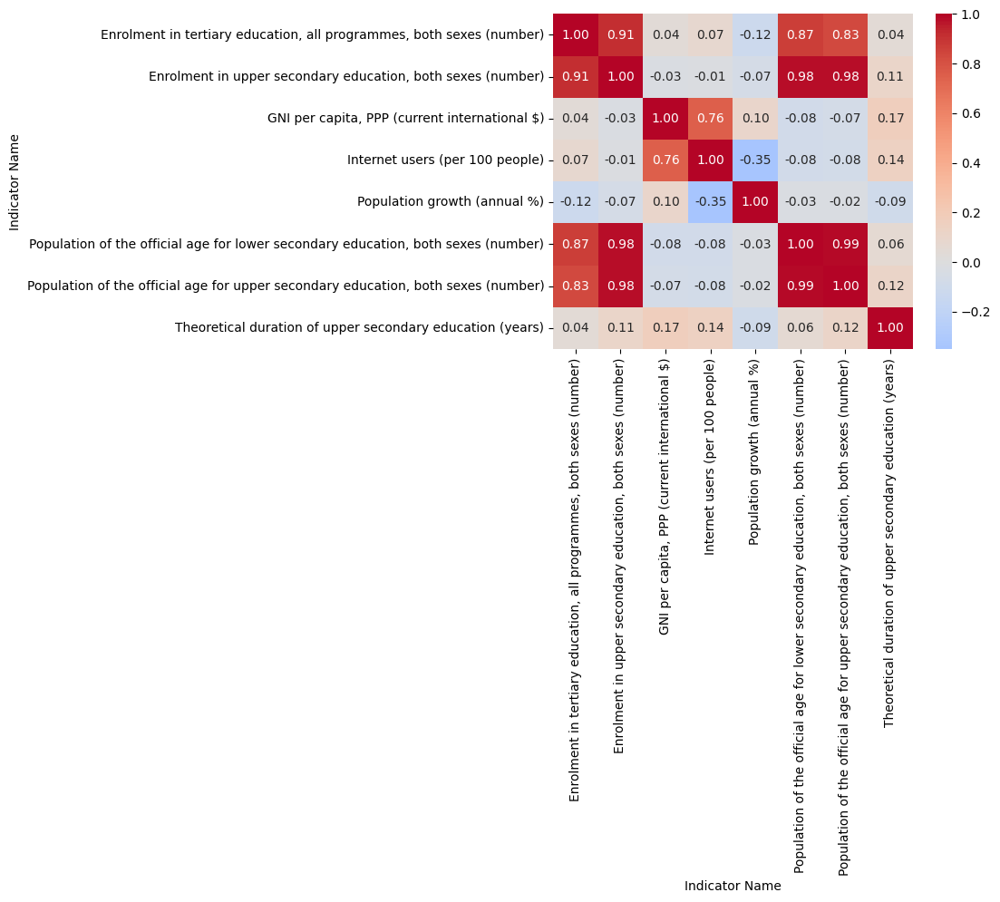

In [238]:
correlation_pearson = gld_Data.corr(method='pearson', min_periods=1)
sbn.heatmap(correlation_pearson, annot=True , fmt=".2f", cmap= "coolwarm", center = 0)

Le coefficient de corrélation de Pearson mesure à quel point deux variables varient ensemble de façon linéaire. Il indique si une variable augmente ou diminue proportionnellement à une autre. Sa valeur va de -1 (relation inverse parfaite) à +1 (relation directe parfaite), et 0 signifie aucune relation linéaire. Le coefficient de Spearman, lui, mesure si deux variables évoluent dans le même ordre (relation monotone), même si ce n’est pas proportionnel. Il est utile quand les données ne suivent pas une relation linéaire ou contiennent des valeurs extrêmes.
Comme tous mes indicateurs suivent une relation linéaire, j’ai choisi de ne pas calculer la matrice de corrélation de Spearman, et de me concentrer uniquement sur celle de Pearson.

Attention ! Le coefficient de corrélation, à lui seul, ne suffit pas à justifier la suppression d’un indicateur dans un cas réel. D’autres éléments doivent être pris en compte, comme la significativité statistique des relations, la pertinence théorique des variables, ou encore leur valeur explicative dans le modèle.

In [239]:
indicators_to_drop = [
    "Population of the official age for lower secondary education, both sexes (number)",
    "Enrolment in upper secondary education, both sexes (number)"
]

gld_Data = gld_Data.drop(columns=indicators_to_drop)

In [240]:
gld_Data.columns = [
    "Inscriptions dans l'enseignement supérieur (tous programmes, deux sexes)",
    "RNB par habitant (PPA, $ internationaux)",
    "Utilisateurs d'Internet (pour 100 personnes)",
    "Croissance démographique annuelle (%)",
    "Population en âge du lycée (nombre)",
    "Durée théorique du lycée (années)"
]
print(gld_Data.columns.tolist())

["Inscriptions dans l'enseignement supérieur (tous programmes, deux sexes)", 'RNB par habitant (PPA, $ internationaux)', "Utilisateurs d'Internet (pour 100 personnes)", 'Croissance démographique annuelle (%)', 'Population en âge du lycée (nombre)', 'Durée théorique du lycée (années)']


<Axes: xlabel='Indicator Name', ylabel='Indicator Name'>

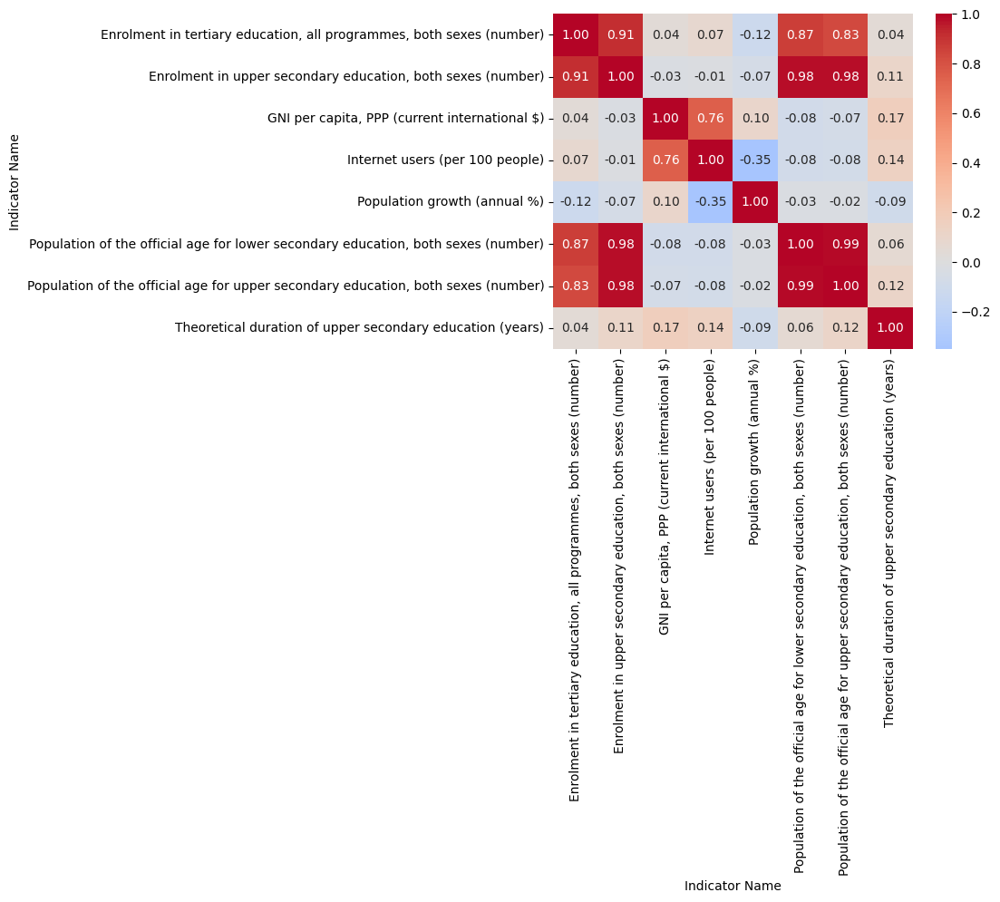

In [241]:
gld_Data.corr(method='pearson', min_periods=1)
sbn.heatmap(correlation_pearson, annot=True , fmt=".2f", cmap= "coolwarm", center = 0)

Même si ces indicateurs sont assez corrélés entre eux, j’ai décidé de les garder quand même parce qu’ils me semblent importants pour l’analyse. "Population of the official age for upper secondary education", "Enrolment in tertiary education", "GNI per capita" et "Internet users" donnent chacun une info différente sur le niveau d’éducation, le développement économique ou l’accès au numérique. Donc même s’ils évoluent ensemble, ils ne disent pas exactement la même chose, et je préfère les garder pour avoir une vision plus complète.

In [242]:
gld_Data[gld_Data["Utilisateurs d'Internet (pour 100 personnes)"] != 0]["Utilisateurs d'Internet (pour 100 personnes)"].describe()


,Utilisateurs d'Internet (pour 100 personnes)
count,195.000000
mean,27.114004
std,22.906106
min,0.585446
25%,7.357761
50%,22.938600
75%,42.534756
max,85.527488


Cette ligne affiche les statistiques descriptives des utilisateurs d'Internet par pays, en excluant ceux dont la valeur est égale à zéro (la valeur 0 correspond aux pays non renseignées aucun pays n'a 0 utilisateur). Les données montrent que parmi 195 pays, le nombre moyen d'utilisateurs d'Internet pour 100 personnes est de 27,1, avec une forte dispersion (écart-type de 22,9). La moitié des pays ont moins de 23 utilisateurs pour 100 personnes, tandis que les 25 % les mieux connectés dépassent 42,5.

/tmp/ipython-input-4118778449.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=gld_Data, x="Utilisateurs d'Internet (pour 100 personnes)", palette='muted')


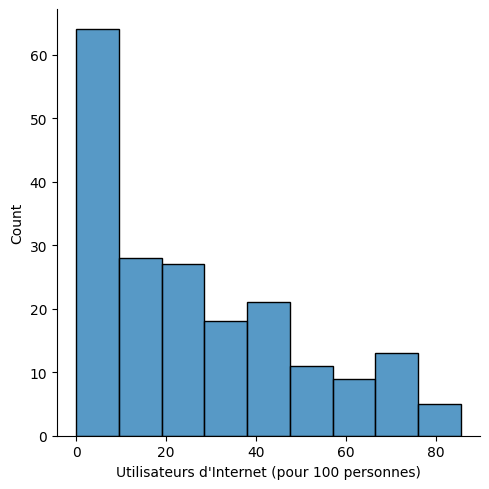

In [243]:
sbn.displot(data=gld_Data, x="Utilisateurs d'Internet (pour 100 personnes)", palette='muted')
plt.show()

Ce code trace un histogramme de la distribution du nombre d'utilisateurs d'Internet par pays. Qui permet de mieux visualiser les explications précédentes.

In [244]:
def describe_statistics(df):
  for indicator in df.columns:
    display(df[indicator].describe())
    min_val = df[indicator].min()
    max_val = df[indicator].max()
    spread = max_val - min_val
    width = min(12, max(6, spread / 1000))
    sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)
    plt.show()

Ce code définit une fonction qui, pour chaque indicateur du DataFrame, affiche ses statistiques descriptives, calcule son étendue (écart entre minimum et maximum), ajuste dynamiquement la largeur du graphique en fonction de cette étendue, puis trace un histogramme de sa distribution avec Seaborn.

,"Inscriptions dans l'enseignement supérieur (tous programmes, deux sexes)"
count,1.870000e+02
mean,8.536479e+05
std,2.757351e+06
min,4.080000e+02
25%,1.468539e+04
50%,1.385167e+05
75%,4.441568e+05
max,2.511269e+07


/tmp/ipython-input-663950770.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)


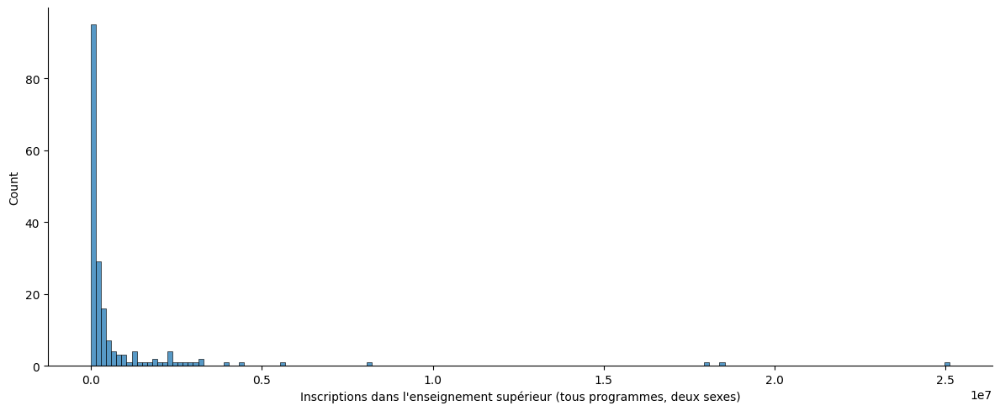

,"RNB par habitant (PPA, $ internationaux)"
count,187.000000
mean,15192.966896
std,17812.778783
min,532.500000
25%,3088.125000
50%,8428.125000
75%,18719.375000
max,109454.166667


/tmp/ipython-input-663950770.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)


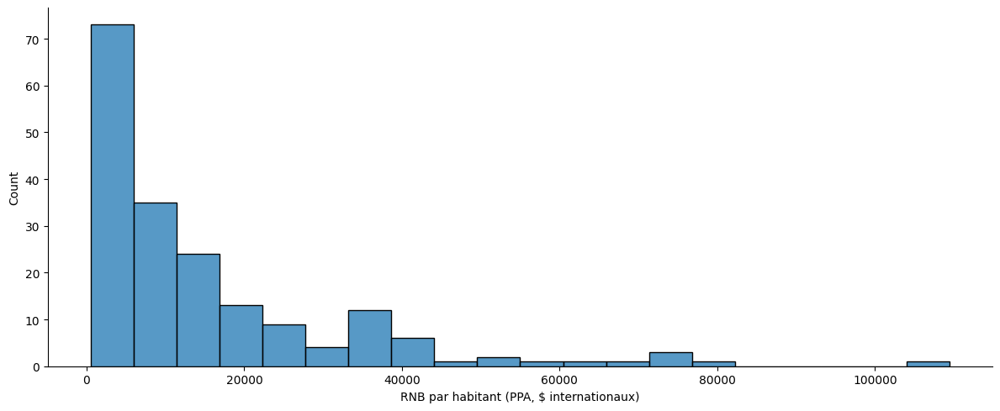

,Utilisateurs d'Internet (pour 100 personnes)
count,196.000000
mean,26.975667
std,22.929236
min,0.000000
25%,7.337646
50%,22.508106
75%,42.474576
max,85.527488


/tmp/ipython-input-663950770.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)


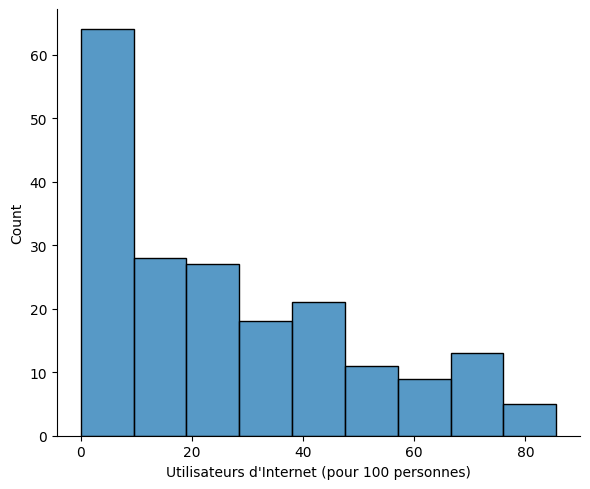

,Croissance démographique annuelle (%)
count,196.000000
mean,1.487603
std,1.361946
min,-1.207886
25%,0.593441
50%,1.347413
75%,2.339506
max,9.199803


/tmp/ipython-input-663950770.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)


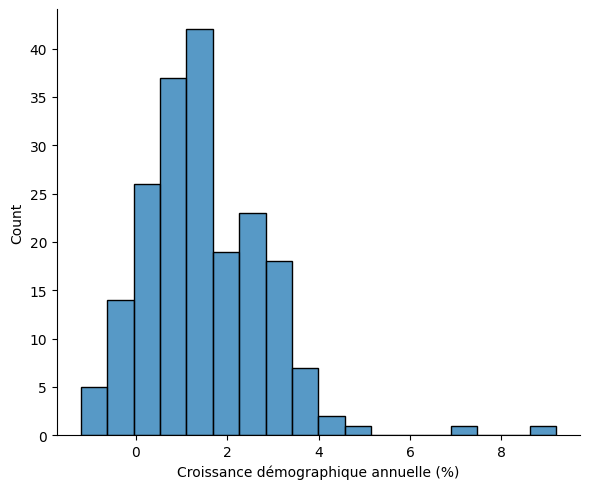

,Population en âge du lycée (nombre)
count,1.930000e+02
mean,2.000685e+06
std,8.460603e+06
min,6.060625e+02
25%,8.763531e+04
50%,3.523878e+05
75%,1.272941e+06
max,9.439154e+07


/tmp/ipython-input-663950770.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)


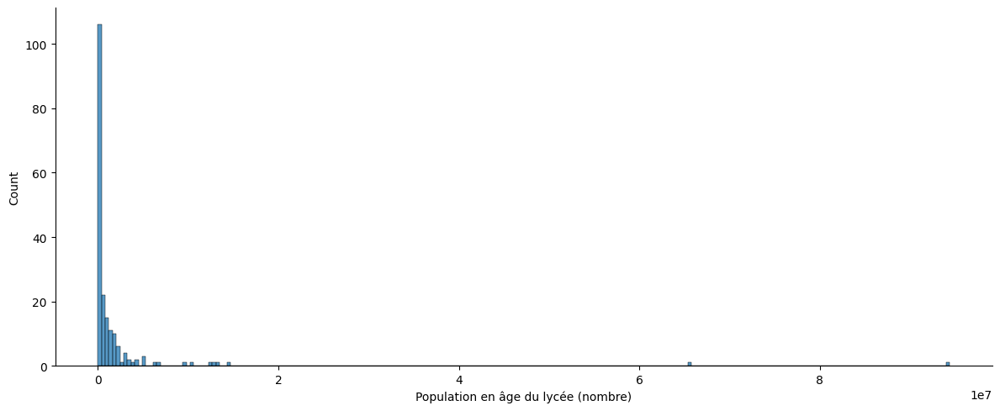

,Durée théorique du lycée (années)
count,196.000000
mean,2.986288
std,0.756298
min,1.000000
25%,2.234375
50%,3.000000
75%,3.453125
max,5.000000


/tmp/ipython-input-663950770.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sbn.displot(data=df, x=indicator, palette='muted', aspect=width / 5)


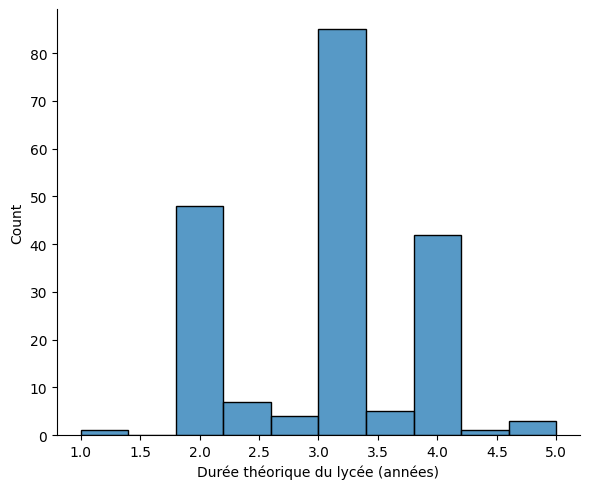

In [245]:
describe_statistics(gld_Data)

## Analyse des distributions par indicateur

### Inscriptions dans l'enseignement supérieur
La distribution est fortement asymétrique, même si la moyenne est élevée (853647), la médiane est bien plus basse (138517), ce qui indique que quelques pays très peuplés tirent la moyenne vers le haut.

### RNB par habitant (PPA, $ internationaux)
Le revenu national brut par habitant varie considérablement, avec une médiane de 8428\$ et un maximum dépassant les 109000\$, révélant de fortes disparités économiques entre les pays.

### Utilisateurs d'Internet (pour 100 personnes)
L’accès à Internet est très inégal : la moitié des pays ont moins de 22 utilisateurs pour 100 personnes, tandis que les mieux connectés dépassent les 85, illustrant une fracture numérique mondiale.

### Croissance démographique annuelle (%)
La croissance démographique est globalement modérée (moyenne de 1,49%), mais certains pays affichent des taux très élevés (jusqu’à 9,2%), alors que d’autres sont en déclin.

### Population en âge du secondaire supérieur
La population en âge d’aller au lycée varie fortement selon les pays, avec une moyenne de 2 millions mais une médiane bien plus basse (352000), ce qui reflète les écarts démographiques.

### Durée théorique du secondaire supérieur
La durée théorique du lycée est relativement homogène, centrée autour de 3 ans, avec quelques variations allant de 1 à 5 ans selon les systèmes éducatifs nationaux.


In [246]:
def plot_top10_by_indicator(df):
    for indicator in df.columns:
        top10 = df[indicator].sort_values(ascending=False).head(10)
        plt.figure(figsize=(10, 6))
        sbn.barplot(x=top10.values, y=top10.index, palette='muted')
        plt.title(f"Top 10 pays pour : {indicator}")
        plt.xlabel(indicator)
        plt.ylabel("Pays")
        plt.tight_layout()
        plt.show()


Cette fonction parcourt chaque indicateur du DataFrame et affiche un graphique en barres des 10 pays les mieux classés pour cet indicateur, en les triant par ordre décroissant et en visualisant leurs valeurs avec Seaborn.


/tmp/ipython-input-3953899003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top10.values, y=top10.index, palette='muted')


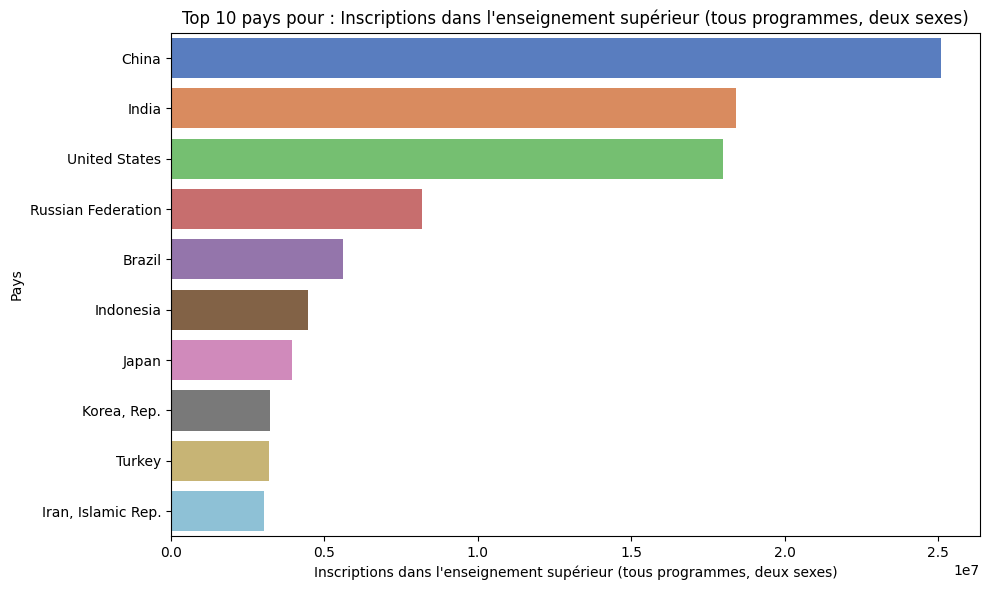

/tmp/ipython-input-3953899003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top10.values, y=top10.index, palette='muted')


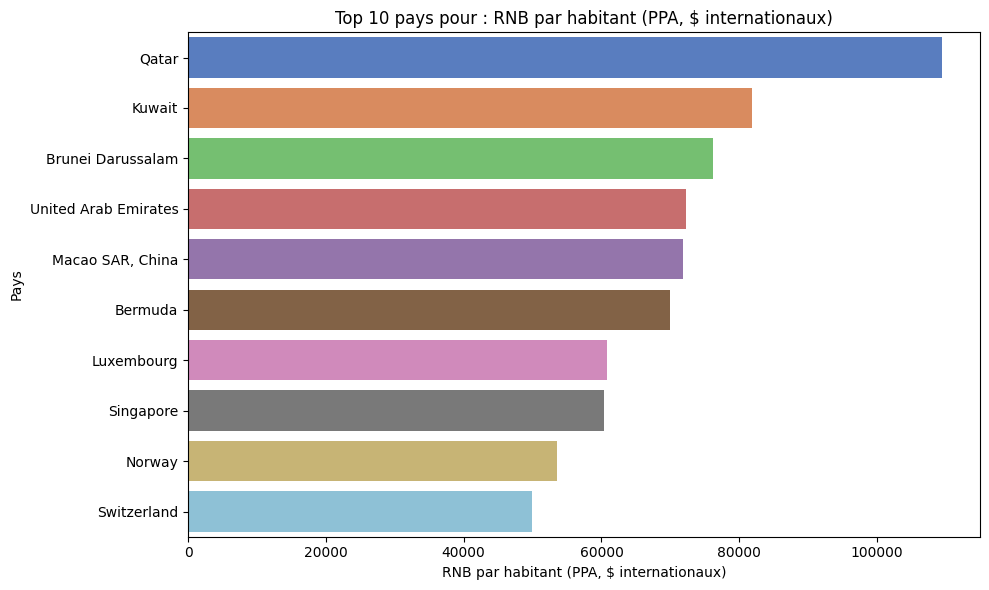

/tmp/ipython-input-3953899003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top10.values, y=top10.index, palette='muted')


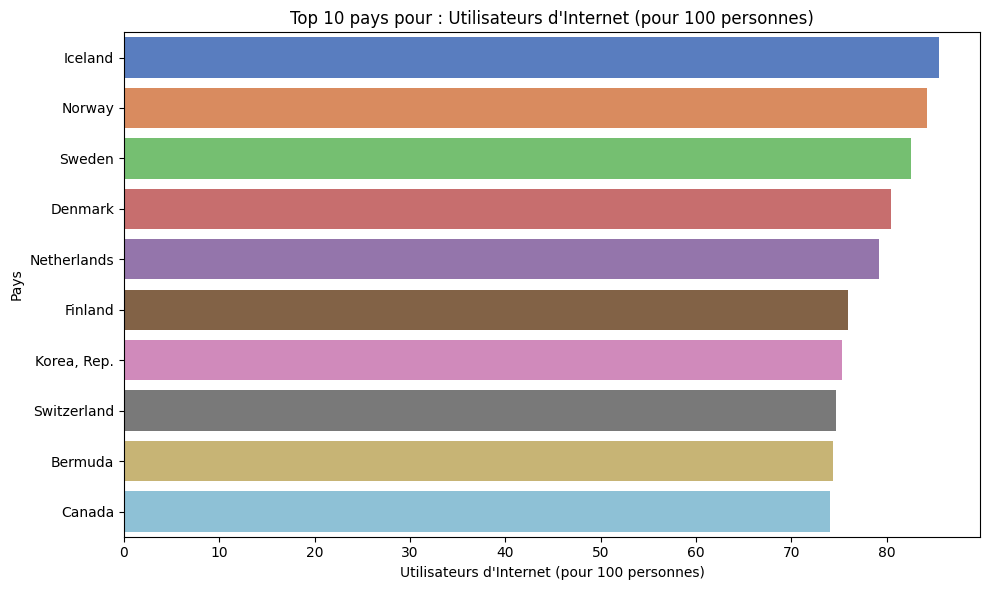

/tmp/ipython-input-3953899003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top10.values, y=top10.index, palette='muted')


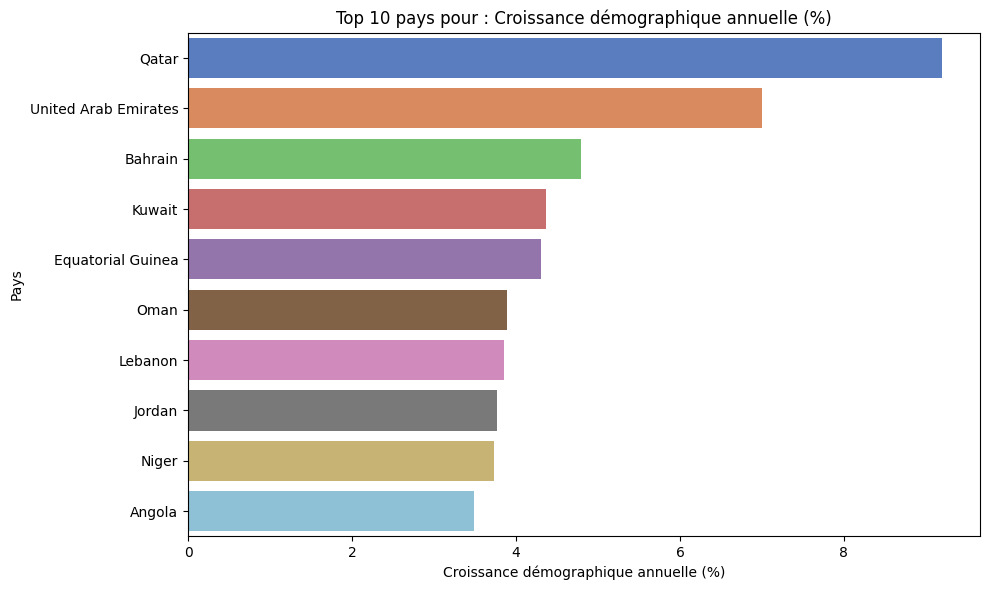

/tmp/ipython-input-3953899003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top10.values, y=top10.index, palette='muted')


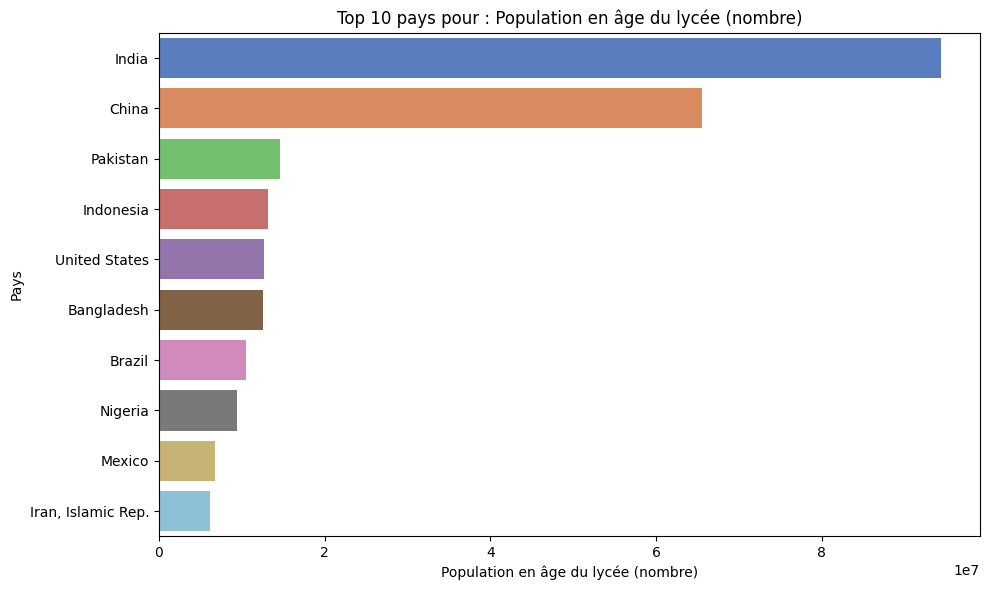

/tmp/ipython-input-3953899003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top10.values, y=top10.index, palette='muted')


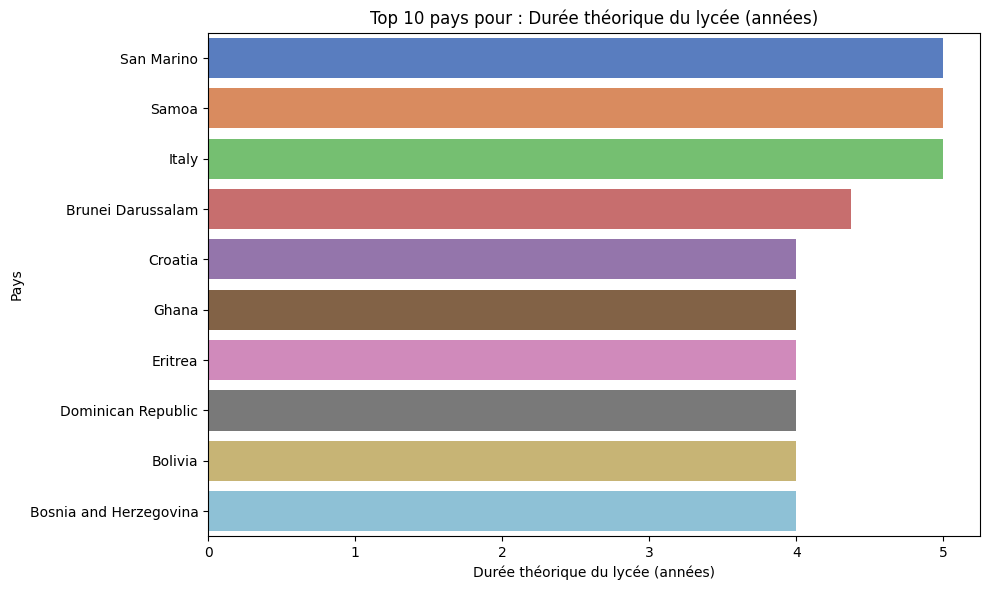

In [247]:
plot_top10_by_indicator(gld_Data)

In [248]:
print(gld_Data.columns)

Index(['Inscriptions dans l'enseignement supérieur (tous programmes, deux sexes)',
       'RNB par habitant (PPA, $ internationaux)',
       'Utilisateurs d'Internet (pour 100 personnes)',
       'Croissance démographique annuelle (%)',
       'Population en âge du lycée (nombre)',
       'Durée théorique du lycée (années)'],
      dtype='object')


In [249]:
def rank_countries_by_indicators(df):
    ranks = df.rank(ascending=False, method='min')
    total_score = ranks.sum(axis=1)
    result = df.copy()
    result['Total Score'] = total_score
    top10 = result.sort_values(by='Total Score').head(10)
    return top10[['Total Score']]


Cette fonction attribue un rang à chaque pays pour chaque indicateur (rang 1 = meilleure valeur), puis calcule un score global en additionnant ces rangs. Elle retourne les 10 pays ayant obtenu les meilleurs classements cumulés, c’est-à-dire ceux avec les scores totaux les plus faibles.

/tmp/ipython-input-1181736943.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sbn.barplot(x=top_10_global["Total Score"], y=top_10_global.index, palette='muted')


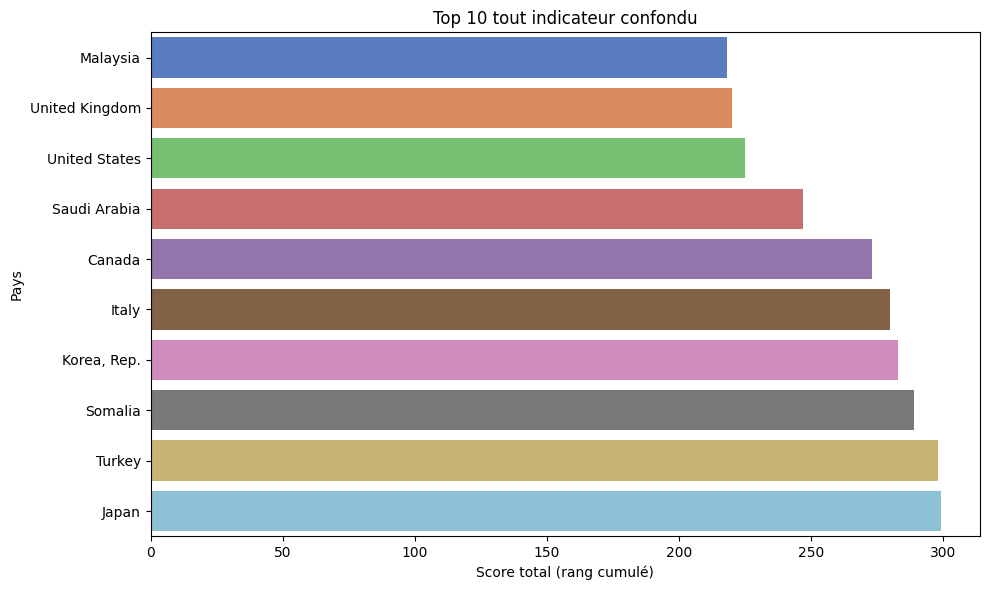

In [250]:
top_10_global = rank_countries_by_indicators(gld_Data)

plt.figure(figsize=(10, 6))
sbn.barplot(x=top_10_global["Total Score"], y=top_10_global.index, palette='muted')
plt.title("Top 10 tout indicateur confondu")
plt.xlabel("Score total (rang cumulé)")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()


Ce code affiche un graphique en barres des 10 pays les mieux classés selon l’ensemble des indicateurs, en utilisant leur score global (somme des rangs). Chaque barre représente un pays, et plus le score est bas, plus le pays est performant globalement.

In [251]:
!pip freeze > requirements.txt

In [252]:
!cat requirements.txt

absl-py==1.4.0
absolufy-imports==0.3.1
accelerate==1.10.1
aiofiles==24.1.0
aiohappyeyeballs==2.6.1
aiohttp==3.13.0
aiosignal==1.4.0
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.11.2
alembic==1.16.5
altair==5.5.0
annotated-types==0.7.0
antlr4-python3-runtime==4.9.3
anyio==4.11.0
anywidget==0.9.18
argcomplete==3.6.2
argon2-cffi==25.1.0
argon2-cffi-bindings==25.1.0
array_record==0.8.1
arrow==1.3.0
arviz==0.22.0
astropy==7.1.0
astropy-iers-data==0.2025.10.6.0.35.25
astunparse==1.6.3
atpublic==5.1
attrs==25.4.0
audioread==3.0.1
Authlib==1.6.5
autograd==1.8.0
babel==2.17.0
backcall==0.2.0
beartype==0.22.2
beautifulsoup4==4.13.5
betterproto==2.0.0b6
bigframes==2.24.0
bigquery-magics==0.10.3
bleach==6.2.0
blinker==1.9.0
blis==1.3.0
blobfile==3.1.0
blosc2==3.10.0
bokeh==3.7.3
Bottleneck==1.4.2
bqplot==0.12.45
branca==0.8.2
Brotli==1.1.0
build==1.3.0
CacheControl==0.14.3
cachetools==5.5.2
catalogue==2.0.10
certifi==2025.10.5
cffi==2.0.0
chardet==5.2.0
charset-normalizer==3.4